In [2]:
# Installation des dependances manquantes sur Google Colab
!pip install optuna shap -q


[notice] A new release of pip is available: 23.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Projet 1 — Prediction des Retards de Vols
## Partie 2 — Deep Learning

**Objectif :** Predire si un vol sera :
- `0` : A l'heure (retard < 15 min)
- `1` : Retard modere (15-30 min)
- `2` : Retard important (> 30 min)

**Architectures implementees :**
- MLP (Multi-Layer Perceptron) en PyTorch — avec Optuna
- LSTM / GRU (series temporelles)
- Transformer Time Series

**Techniques :** EarlyStopping, ReduceLROnPlateau, Dropout, BatchNorm, SHAP


## 0. Imports & Configuration

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

try:
    import shap
    SHAP_OK = True
except ImportError:
    SHAP_OK = False

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device utilise : {DEVICE}")

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = ['#2196F3', '#FF9800', '#4CAF50']
CLASS_NAMES = ["A l'heure", "Retard +15min", "Retard +30min"]


Device utilise : cpu


## 1. Chargement & Preparation des donnees

In [4]:
DATA_PATH = "flights_cleaned_encoded.csv"

# 50 000 lignes pour garder des temps d'execution raisonnables
df = pd.read_csv(DATA_PATH, nrows=50_000)
print(f"Shape : {df.shape}")
print("\nDistribution DELAY_CLASS :")
print(df['DELAY_CLASS'].value_counts(normalize=True).round(3))
df.head(3)


Shape : (50000, 33)

Distribution DELAY_CLASS :
DELAY_CLASS
0    0.693
2    0.192
1    0.115
Name: proportion, dtype: float64


,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,...,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN,DAY_PERIOD_evening,DAY_PERIOD_morning,DAY_PERIOD_night
0,2015,1,1,4,98,5,-11.0,205.0,1448.0,430,...,0,0,0,0,0,0,0,0,0,1
1,2015,1,1,4,2336,10,-8.0,280.0,2085.0,750,...,0,0,0,0,0,0,0,0,0,1
2,2015,1,1,4,840,20,-2.0,286.0,2085.0,806,...,0,0,0,0,1,0,0,0,0,1


In [5]:
TARGET = 'DELAY_CLASS'
DROP_COLS = [TARGET, 'DEPARTURE_DELAY', 'YEAR']   # DEPARTURE_DELAY = data leakage !

FEATURES = [c for c in df.columns if c not in DROP_COLS]
print(f"Nombre de features : {len(FEATURES)}")

X = df[FEATURES].values.astype(np.float32)
y = df[TARGET].values.astype(np.int64)

# Split 80 / 10 / 10
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.20,
                                              random_state=SEED, stratify=y)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50,
                                              random_state=SEED, stratify=y_tmp)
print(f"Train: {X_tr.shape}  Val: {X_val.shape}  Test: {X_te.shape}")

# Normalisation
scaler = StandardScaler()
X_tr  = scaler.fit_transform(X_tr).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_te  = scaler.transform(X_te).astype(np.float32)

# Poids de classes (desequilibre)
cw = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
print(f"Class weights : {cw.round(3)}")


Nombre de features : 30
Train: (40000, 30)  Val: (5000, 30)  Test: (5000, 30)
Class weights : [0.481 2.907 1.732]


In [6]:
BATCH_SIZE = 256

def make_loader(X, y, shuffle=True, bs=BATCH_SIZE):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=0)

train_loader = make_loader(X_tr, y_tr)
val_loader   = make_loader(X_val, y_val, shuffle=False)
test_loader  = make_loader(X_te,  y_te,  shuffle=False)

N_FEATURES = X_tr.shape[1]
N_CLASSES  = 3
SEQ_LEN    = N_FEATURES   # pour LSTM/Transformer
print(f"Features : {N_FEATURES} | Classes : {N_CLASSES}")


Features : 30 | Classes : 3


## 2. Utilitaires : EarlyStopping, boucle d'entrainement, evaluation

In [7]:
class EarlyStopping:
    def __init__(self, patience=7, min_delta=1e-4):
        self.patience  = patience
        self.min_delta = min_delta
        self.counter   = 0
        self.best_loss = np.inf
        self.stop      = False
        self.best_weights = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss    = val_loss
            self.counter      = 0
            self.best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def restore(self, model):
        if self.best_weights:
            model.load_state_dict(self.best_weights)


In [8]:
def train_model(model, train_loader, val_loader,
               n_epochs=60, lr=1e-3, patience=8,
               use_scheduler=True):

    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=4)
    es = EarlyStopping(patience=patience)

    history = {'train_loss': [], 'val_loss': [],
               'train_acc': [],  'val_acc': [], 'lr': []}

    for epoch in range(1, n_epochs + 1):
        model.train()
        tr_loss, tr_correct, tr_total = 0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out  = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tr_loss    += loss.item() * len(yb)
            tr_correct += (out.argmax(1) == yb).sum().item()
            tr_total   += len(yb)

        model.eval()
        v_loss, v_correct, v_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out    = model(xb)
                loss   = criterion(out, yb)
                v_loss    += loss.item() * len(yb)
                v_correct += (out.argmax(1) == yb).sum().item()
                v_total   += len(yb)

        tl = tr_loss / tr_total;  ta = tr_correct / tr_total
        vl = v_loss  / v_total;   va = v_correct  / v_total
        current_lr = optimizer.param_groups[0]['lr']
        history['train_loss'].append(tl);  history['val_loss'].append(vl)
        history['train_acc'].append(ta);   history['val_acc'].append(va)
        history['lr'].append(current_lr)

        if use_scheduler:
            scheduler.step(vl)
        es(vl, model)

        if es.stop:
            break

    es.restore(model)
    return history


In [9]:
def evaluate_model(model, loader, label="Test"):
    model.eval()
    all_preds, all_probs, all_true = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            out   = model(xb)
            probs = torch.softmax(out, dim=1).cpu().numpy()
            preds = out.argmax(1).cpu().numpy()
            all_probs.append(probs); all_preds.append(preds); all_true.append(yb.numpy())

    y_true  = np.concatenate(all_true)
    y_pred  = np.concatenate(all_preds)
    y_proba = np.concatenate(all_probs)

    print(f"\n{'='*55}  {label}  {'='*55}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
    roc = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
    print(f"ROC-AUC macro : {roc:.4f}")
    return y_true, y_pred, y_proba


def plot_learning_curves(history, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f"Courbes d'apprentissage - {title}", fontsize=13, fontweight='bold')
    ep = range(1, len(history['train_loss']) + 1)
    axes[0].plot(ep, history['train_loss'], label='Train', color=COLORS[0])
    axes[0].plot(ep, history['val_loss'],   label='Val',   color=COLORS[1])
    axes[0].set_title("Loss"); axes[0].legend()
    axes[1].plot(ep, history['train_acc'],  label='Train', color=COLORS[0])
    axes[1].plot(ep, history['val_acc'],    label='Val',   color=COLORS[1])
    axes[1].set_title("Accuracy"); axes[1].legend()
    axes[2].plot(ep, history['lr'], color=COLORS[2])
    axes[2].set_title("Learning Rate (ReduceLROnPlateau)")
    plt.tight_layout(); plt.show()


def plot_full_evaluation(y_true, y_pred, y_proba, title=""):
    fig = plt.figure(figsize=(18, 5))
    fig.suptitle(f"Analyse complete - {title}", fontsize=13, fontweight='bold')
    gs  = gridspec.GridSpec(1, 3, figure=fig)

    ax0 = fig.add_subplot(gs[0])
    cm  = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax0, colorbar=False, cmap='Blues')
    ax0.set_title("Matrice de Confusion")

    ax1 = fig.add_subplot(gs[1])
    for i, (cls, col) in enumerate(zip(CLASS_NAMES, COLORS)):
        y_bin = (y_true == i).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, y_proba[:, i])
        auc = roc_auc_score(y_bin, y_proba[:, i])
        ax1.plot(fpr, tpr, label=f"{cls} (AUC={auc:.3f})", color=col)
    ax1.plot([0,1],[0,1],'k--', lw=0.8)
    ax1.set_title("ROC (One-vs-Rest)"); ax1.legend(fontsize=8)

    ax2 = fig.add_subplot(gs[2])
    for i, (cls, col) in enumerate(zip(CLASS_NAMES, COLORS)):
        y_bin = (y_true == i).astype(int)
        prec, rec, _ = precision_recall_curve(y_bin, y_proba[:, i])
        ap = average_precision_score(y_bin, y_proba[:, i])
        ax2.plot(rec, prec, label=f"{cls} (AP={ap:.3f})", color=col)
    ax2.set_title("Precision-Recall"); ax2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print("\nAnalyse du cout des Faux Negatifs (vols retardes non detectes):")
    for i in [1, 2]:
        fn = ((y_true == i) & (y_pred == 0)).sum()
        total = (y_true == i).sum()
        rate  = fn / total if total > 0 else 0
        print(f"  {CLASS_NAMES[i]} : {fn} FN sur {total} reels -> taux non detecte = {rate:.2%}")


## 3. Modele 1 — MLP (Multi-Layer Perceptron) avec Optuna

In [10]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden1=256, hidden2=128, hidden3=64,
                 dropout=0.3, n_classes=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden1), nn.BatchNorm1d(hidden1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2), nn.BatchNorm1d(hidden2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden2, hidden3), nn.BatchNorm1d(hidden3), nn.ReLU(), nn.Dropout(dropout/2),
            nn.Linear(hidden3, n_classes)
        )
    def forward(self, x): return self.net(x)

total_params = sum(p.numel() for p in MLP(N_FEATURES).parameters() if p.requires_grad)
print(f"MLP parametres entrainables (config defaut) : {total_params:,}")


MLP parametres entrainables (config defaut) : 50,179


### 3.1 Recherche d'hyperparametres — Optuna

In [11]:
def mlp_objective(trial):
    h1 = trial.suggest_categorical('h1', [128, 256, 512])
    h2 = trial.suggest_categorical('h2', [64, 128, 256])
    h3 = trial.suggest_categorical('h3', [32, 64, 128])
    dr = trial.suggest_float('dropout', 0.1, 0.5, step=0.1)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)

    model = MLP(N_FEATURES, h1, h2, h3, dr).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.5, patience=3)

    for epoch in range(20):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval(); v_loss = 0; n = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                v_loss += criterion(model(xb), yb).item() * len(yb); n += len(yb)
        vl = v_loss / n
        scheduler.step(vl)
        trial.report(vl, epoch)
        if trial.should_prune(): raise optuna.TrialPruned()
    return vl

print("Optuna - recherche HP MLP (20 trials x 20 epoques)...")
study_mlp = optuna.create_study(direction='minimize',
              pruner=optuna.pruners.MedianPruner(n_warmup_steps=5))
study_mlp.optimize(mlp_objective, n_trials=20)
best_mlp = study_mlp.best_params
print("Meilleurs HP:", best_mlp)


Optuna - recherche HP MLP (20 trials x 20 epoques)...


Meilleurs HP: {'h1': 128, 'h2': 64, 'h3': 32, 'dropout': 0.1, 'lr': 0.0014717791675860226}


### 3.2 Entrainement final MLP

In [12]:
mlp_model = MLP(N_FEATURES,
                hidden1=best_mlp['h1'],
                hidden2=best_mlp['h2'],
                hidden3=best_mlp['h3'],
                dropout=best_mlp['dropout']).to(DEVICE)

print("Entrainement MLP final...")
hist_mlp = train_model(mlp_model, train_loader, val_loader,
                       n_epochs=80, lr=best_mlp['lr'], patience=10)


Entrainement MLP final...


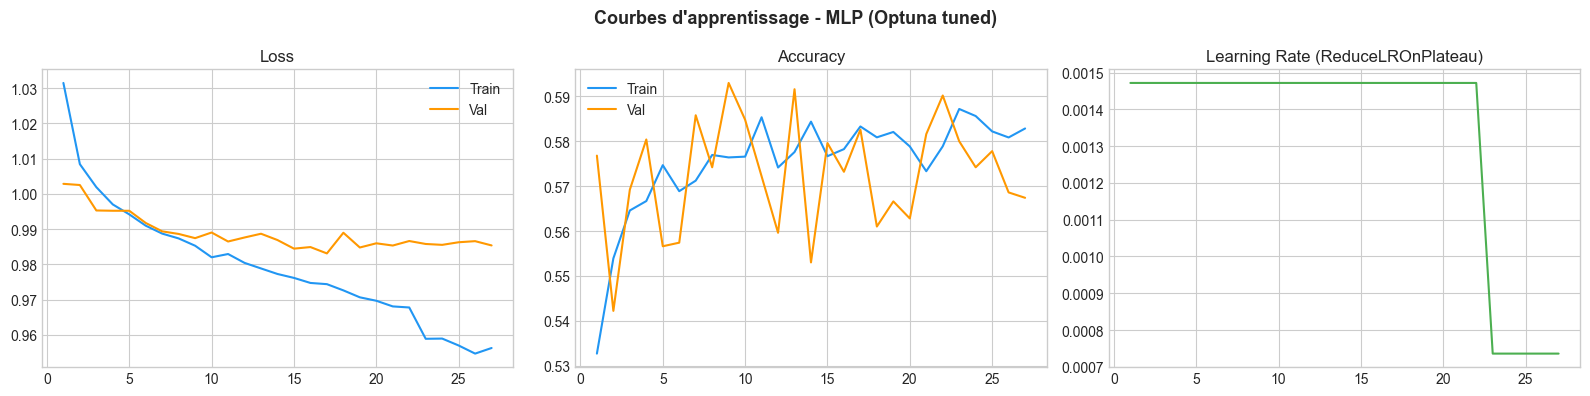


=======================================================  MLP  =======================================================
               precision    recall  f1-score   support

    A l'heure       0.85      0.67      0.75      3465
Retard +15min       0.15      0.32      0.21       573
Retard +30min       0.42      0.49      0.45       962

     accuracy                           0.59      5000
    macro avg       0.48      0.49      0.47      5000
 weighted avg       0.69      0.59      0.63      5000

ROC-AUC macro : 0.7213


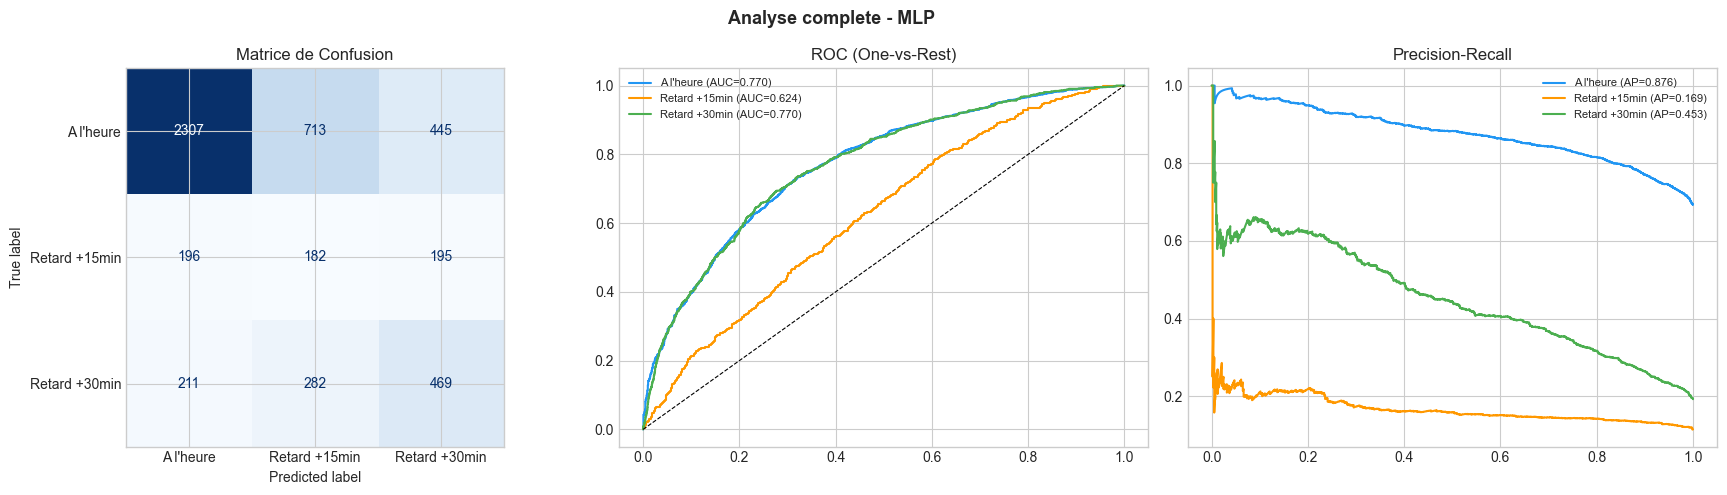


Analyse du cout des Faux Negatifs (vols retardes non detectes):
  Retard +15min : 196 FN sur 573 reels -> taux non detecte = 34.21%
  Retard +30min : 211 FN sur 962 reels -> taux non detecte = 21.93%


In [13]:
plot_learning_curves(hist_mlp, "MLP (Optuna tuned)")
y_true_mlp, y_pred_mlp, y_proba_mlp = evaluate_model(mlp_model, test_loader, "MLP")
plot_full_evaluation(y_true_mlp, y_pred_mlp, y_proba_mlp, "MLP")


## 4. Modele 2 — LSTM & GRU (Series Temporelles)

Chaque feature = un pas de temps -> sequence (batch, seq_len, 1).


In [14]:
def make_seq_loader(X, y, shuffle=True, bs=BATCH_SIZE):
    Xt = torch.tensor(X).unsqueeze(-1)   # (N, seq_len, 1)
    ds = TensorDataset(Xt, torch.tensor(y))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=0)

seq_train = make_seq_loader(X_tr,  y_tr)
seq_val   = make_seq_loader(X_val, y_val, shuffle=False)
seq_test  = make_seq_loader(X_te,  y_te,  shuffle=False)
print(f"Format sequence : (batch, {SEQ_LEN}, 1)")


Format sequence : (batch, 30, 1)


In [15]:
class RNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2,
                 dropout=0.3, n_classes=3, rnn_type='LSTM'):
        super().__init__()
        RNN = nn.LSTM if rnn_type == 'LSTM' else nn.GRU
        self.rnn = RNN(input_size, hidden_size, num_layers=num_layers,
                       batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32), nn.ReLU(),
            nn.Dropout(dropout/2), nn.Linear(32, n_classes)
        )

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(self.dropout(out[:, -1, :]))

lstm_model = RNNModel(rnn_type='LSTM').to(DEVICE)
gru_model  = RNNModel(rnn_type='GRU').to(DEVICE)
print(f"LSTM params : {sum(p.numel() for p in lstm_model.parameters()):,}")
print(f"GRU  params : {sum(p.numel() for p in gru_model.parameters()):,}")


LSTM params : 52,611
GRU  params : 40,003


### 4.1 Entrainement LSTM

In [16]:
print("Entrainement LSTM...")
hist_lstm = train_model(lstm_model, seq_train, seq_val,
                        n_epochs=60, lr=5e-4, patience=8)


Entrainement LSTM...


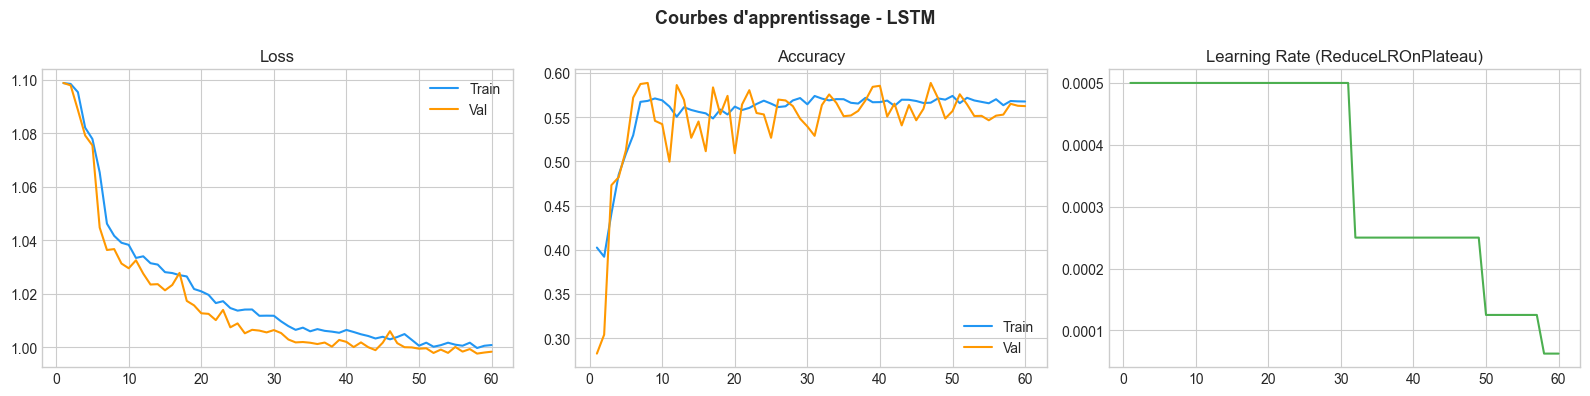


=======================================================  LSTM  =======================================================
               precision    recall  f1-score   support

    A l'heure       0.84      0.64      0.73      3465
Retard +15min       0.15      0.33      0.21       573
Retard +30min       0.43      0.49      0.46       962

     accuracy                           0.58      5000
    macro avg       0.47      0.49      0.46      5000
 weighted avg       0.68      0.58      0.62      5000

ROC-AUC macro : 0.7074


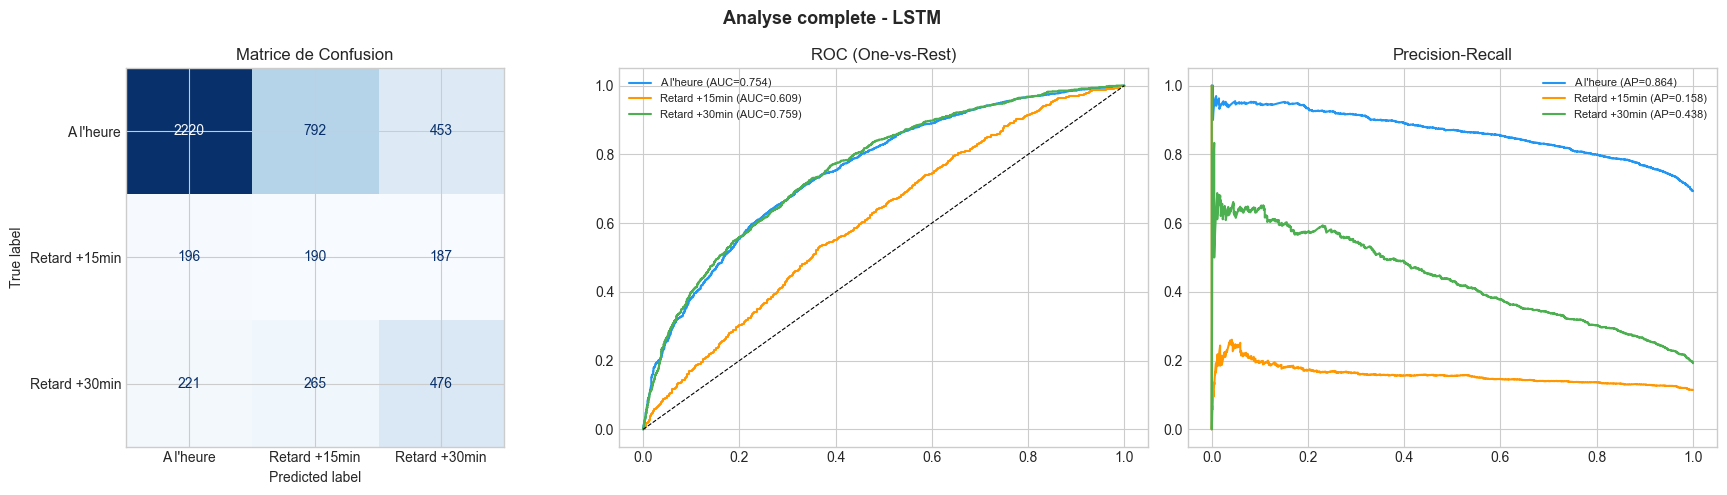


Analyse du cout des Faux Negatifs (vols retardes non detectes):
  Retard +15min : 196 FN sur 573 reels -> taux non detecte = 34.21%
  Retard +30min : 221 FN sur 962 reels -> taux non detecte = 22.97%


In [17]:
plot_learning_curves(hist_lstm, "LSTM")
y_true_lstm, y_pred_lstm, y_proba_lstm = evaluate_model(lstm_model, seq_test, "LSTM")
plot_full_evaluation(y_true_lstm, y_pred_lstm, y_proba_lstm, "LSTM")


### 4.2 Entrainement GRU

In [18]:
print("Entrainement GRU...")
hist_gru = train_model(gru_model, seq_train, seq_val,
                       n_epochs=60, lr=5e-4, patience=8)


Entrainement GRU...


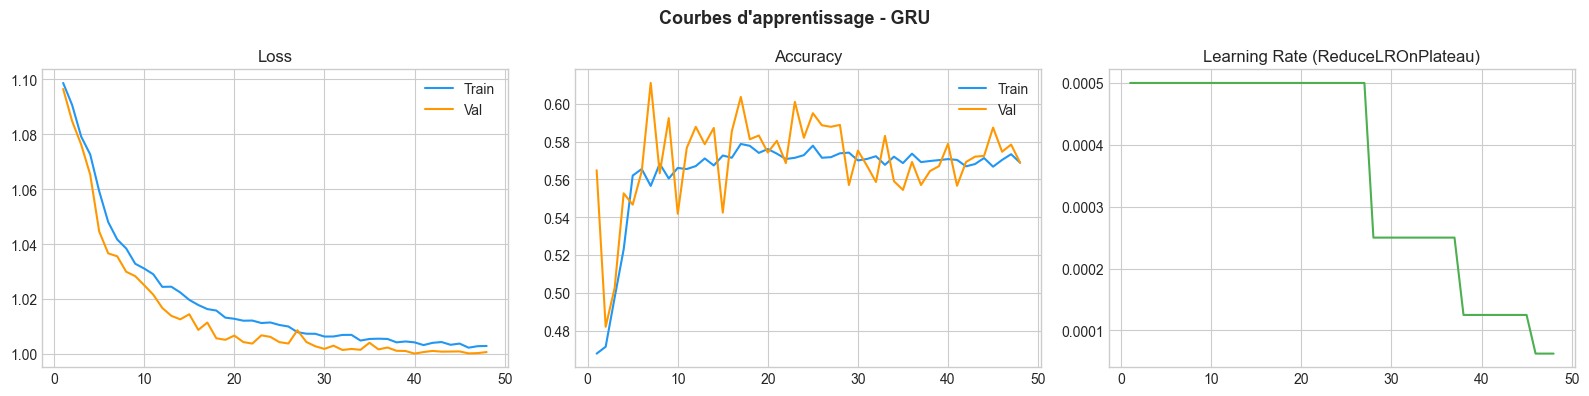


=======================================================  GRU  =======================================================
               precision    recall  f1-score   support

    A l'heure       0.84      0.66      0.74      3465
Retard +15min       0.15      0.33      0.21       573
Retard +30min       0.42      0.47      0.44       962

     accuracy                           0.58      5000
    macro avg       0.47      0.49      0.46      5000
 weighted avg       0.68      0.58      0.62      5000

ROC-AUC macro : 0.7113


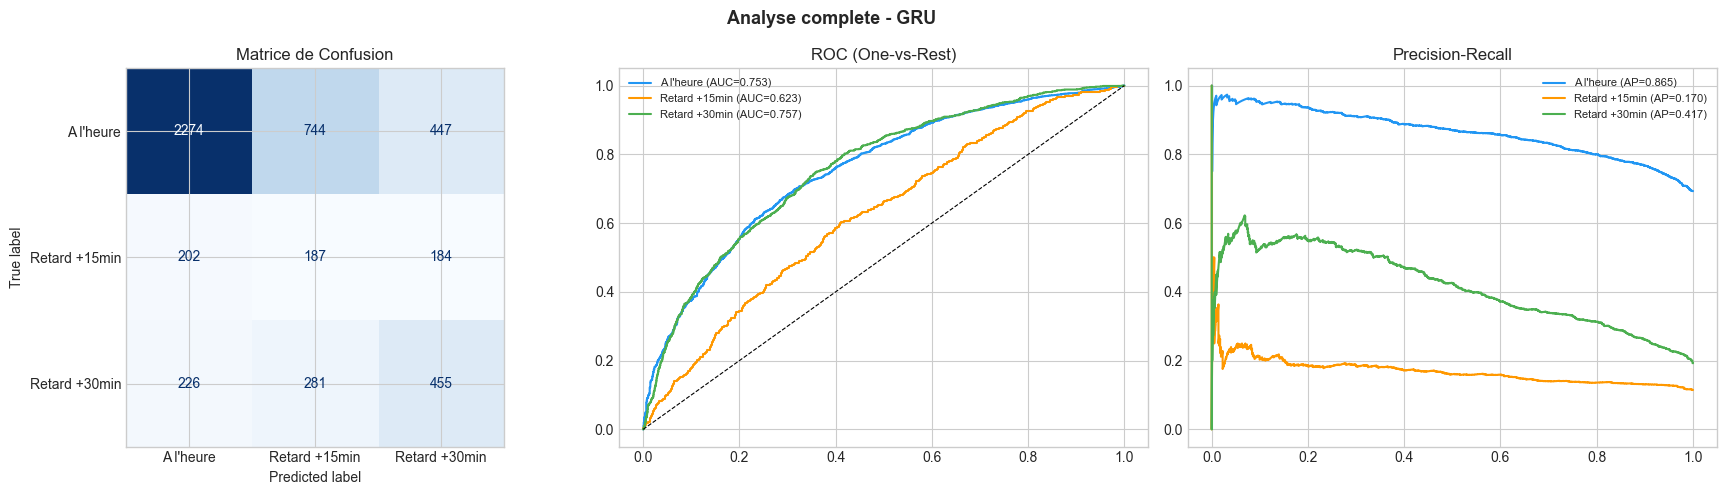


Analyse du cout des Faux Negatifs (vols retardes non detectes):
  Retard +15min : 202 FN sur 573 reels -> taux non detecte = 35.25%
  Retard +30min : 226 FN sur 962 reels -> taux non detecte = 23.49%


In [19]:
plot_learning_curves(hist_gru, "GRU")
y_true_gru, y_pred_gru, y_proba_gru = evaluate_model(gru_model, seq_test, "GRU")
plot_full_evaluation(y_true_gru, y_pred_gru, y_proba_gru, "GRU")


## 5. Modele 3 — Transformer Time Series

Architecture legere : chaque feature = un token de dimension `d_model`.
Encodage positionnel appris + TransformerEncoder + moyenne sur les tokens.


In [20]:
class TransformerClassifier(nn.Module):
    def __init__(self, seq_len, d_model=32, nhead=4, num_layers=2,
                 dropout=0.2, n_classes=3):
        super().__init__()
        self.input_proj = nn.Linear(1, d_model)
        self.pos_emb    = nn.Embedding(seq_len, d_model)
        encoder_layer   = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=d_model*4, dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.norm    = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.head    = nn.Linear(d_model, n_classes)

    def forward(self, x):
        B, S, _ = x.shape
        pos  = torch.arange(S, device=x.device).unsqueeze(0).expand(B, -1)
        x    = self.input_proj(x) + self.pos_emb(pos)
        x    = self.encoder(x)
        x    = self.norm(x.mean(dim=1))
        return self.head(self.dropout(x))

transf_model = TransformerClassifier(seq_len=SEQ_LEN).to(DEVICE)
print(f"Transformer params : {sum(p.numel() for p in transf_model.parameters()):,}")


Transformer params : 26,595


In [21]:
print("Entrainement Transformer...")
hist_transf = train_model(transf_model, seq_train, seq_val,
                          n_epochs=60, lr=3e-4, patience=10)


Entrainement Transformer...


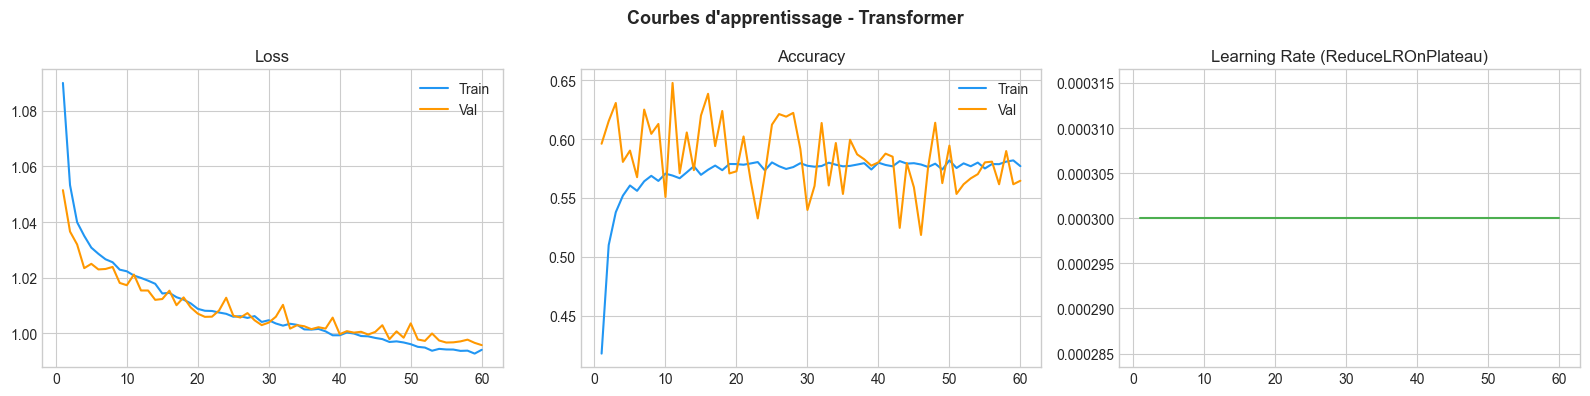


=======================================================  Transformer  =======================================================
               precision    recall  f1-score   support

    A l'heure       0.85      0.63      0.72      3465
Retard +15min       0.16      0.32      0.21       573
Retard +30min       0.41      0.53      0.46       962

     accuracy                           0.58      5000
    macro avg       0.47      0.49      0.46      5000
 weighted avg       0.68      0.58      0.61      5000

ROC-AUC macro : 0.7154


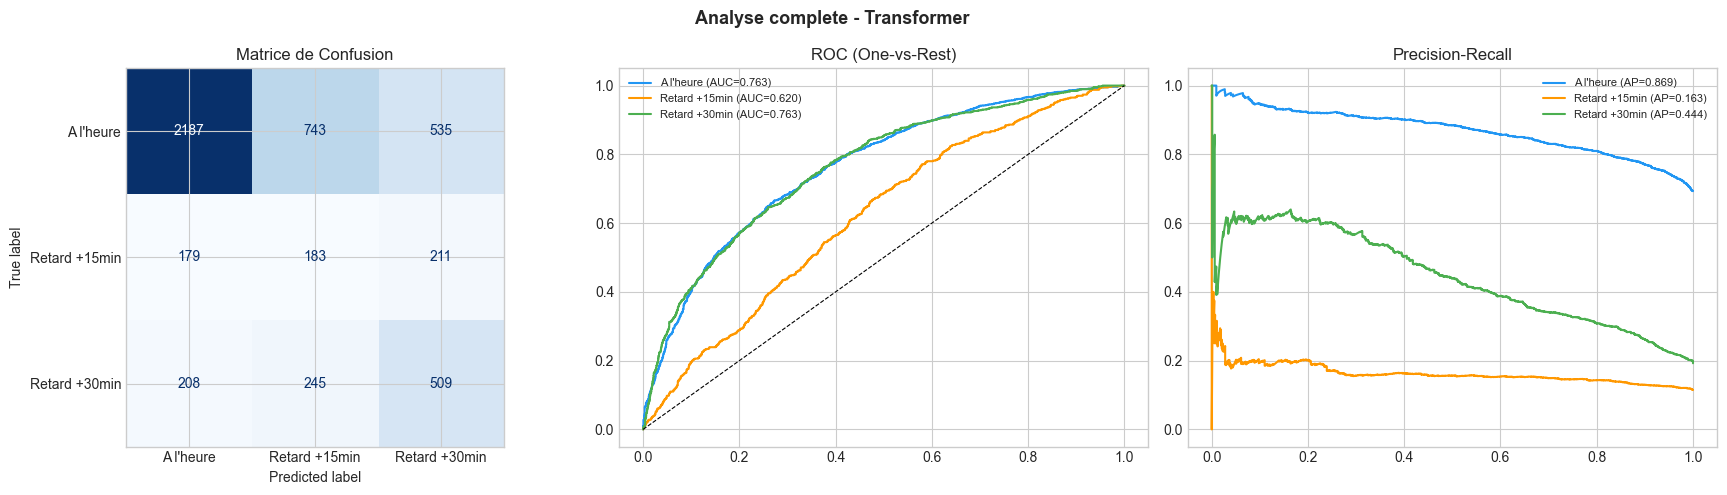


Analyse du cout des Faux Negatifs (vols retardes non detectes):
  Retard +15min : 179 FN sur 573 reels -> taux non detecte = 31.24%
  Retard +30min : 208 FN sur 962 reels -> taux non detecte = 21.62%


In [22]:
plot_learning_curves(hist_transf, "Transformer")
y_true_transf, y_pred_transf, y_proba_transf = evaluate_model(transf_model, seq_test, "Transformer")
plot_full_evaluation(y_true_transf, y_pred_transf, y_proba_transf, "Transformer")


## 6. Etude comparative — Impact de la taille des Batchs

Comparaison de la stabilite des gradients selon `batch_size` : 64 / 256 / 1024.



Batch size = 64
  Val loss: 0.9806  Val acc: 0.5900

Batch size = 256
  Val loss: 0.9827  Val acc: 0.5760

Batch size = 1024
  Val loss: 0.9856  Val acc: 0.5860


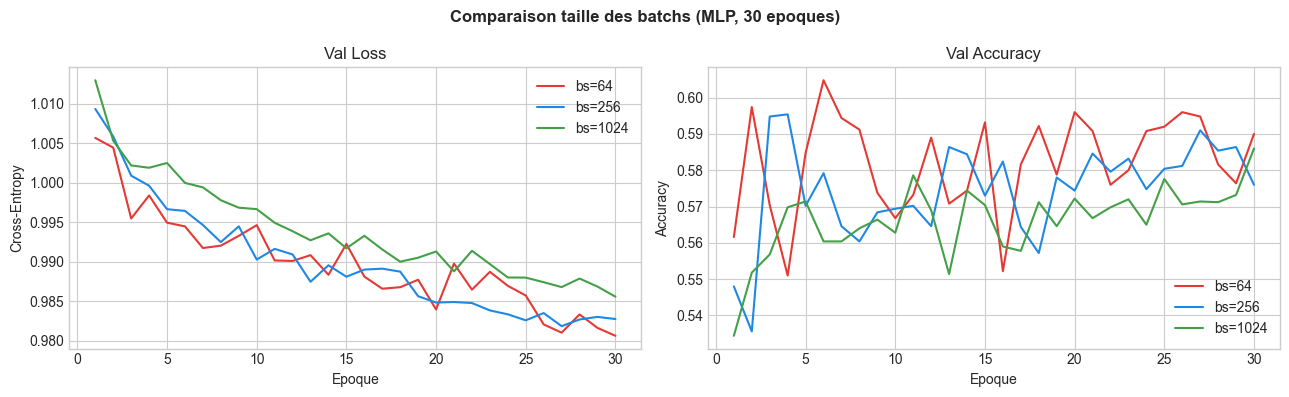


Conclusions :
  bs=64  : gradient bruite, convergence parfois lente, bonne generalisation
  bs=256 : bon equilibre stabilite/generalisation (recommande)
  bs=1024: gradient lisse, convergence rapide, risque de sharp minima


In [23]:
BATCH_SIZES  = [64, 256, 1024]
batch_results = {}

for bs in BATCH_SIZES:
    print(f"\nBatch size = {bs}")
    tl = make_loader(X_tr,  y_tr,  bs=bs)
    vl = make_loader(X_val, y_val, shuffle=False, bs=bs)
    m  = MLP(N_FEATURES, 256, 128, 64, 0.3).to(DEVICE)
    h  = train_model(m, tl, vl, n_epochs=30, lr=1e-3, patience=6)
    batch_results[bs] = h
    print(f"  Val loss: {h['val_loss'][-1]:.4f}  Val acc: {h['val_acc'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Comparaison taille des batchs (MLP, 30 epoques)", fontsize=12, fontweight='bold')
cols = ['#E53935', '#1E88E5', '#43A047']
for (bs, hist), col in zip(batch_results.items(), cols):
    ep = range(1, len(hist['val_loss']) + 1)
    axes[0].plot(ep, hist['val_loss'], label=f"bs={bs}", color=col)
    axes[1].plot(ep, hist['val_acc'],  label=f"bs={bs}", color=col)
for ax, t, yl in zip(axes, ['Val Loss', 'Val Accuracy'], ['Cross-Entropy', 'Accuracy']):
    ax.set_title(t); ax.set_xlabel("Epoque"); ax.set_ylabel(yl); ax.legend()
plt.tight_layout(); plt.show()

print("\nConclusions :")
print("  bs=64  : gradient bruite, convergence parfois lente, bonne generalisation")
print("  bs=256 : bon equilibre stabilite/generalisation (recommande)")
print("  bs=1024: gradient lisse, convergence rapide, risque de sharp minima")


## 7. Analyse par seuil de retard (15 / 30 min)

Analyse par seuil de retard - MLP (meilleur modele)

  A l'heure
    N = 3465  |  Precision classe = 0.666

  Retard +15min
    N = 573  |  Precision classe = 0.318
    Faux Negatifs (non detectes) = 196 (34.2%)

  Retard +30min
    N = 962  |  Precision classe = 0.488
    Faux Negatifs (non detectes) = 211 (21.9%)


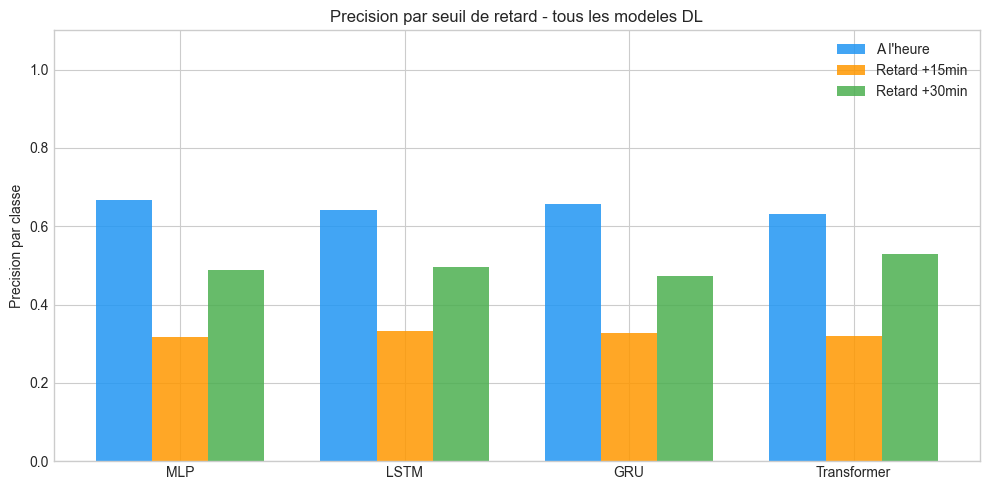

In [24]:
print("Analyse par seuil de retard - MLP (meilleur modele)")
print("="*60)
for cls, label in enumerate(CLASS_NAMES):
    mask = y_true_mlp == cls
    if mask.sum() == 0: continue
    acc_cls = (y_pred_mlp[mask] == cls).mean()
    print(f"\n  {label}")
    print(f"    N = {mask.sum()}  |  Precision classe = {acc_cls:.3f}")
    if cls > 0:
        fn   = ((y_true_mlp == cls) & (y_pred_mlp == 0)).sum()
        rate = fn / mask.sum()
        print(f"    Faux Negatifs (non detectes) = {fn} ({rate:.1%})")

# Barplot par modele
models_names = ['MLP', 'LSTM', 'GRU', 'Transformer']
results_all  = [(y_true_mlp, y_pred_mlp), (y_true_lstm, y_pred_lstm),
                (y_true_gru, y_pred_gru), (y_true_transf, y_pred_transf)]

acc_per_class = {c: [] for c in range(3)}
for yt, yp in results_all:
    for c in range(3):
        mask = yt == c
        acc_per_class[c].append((yp[mask] == c).mean() if mask.sum() > 0 else 0)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(models_names)); w = 0.25
for i, (c, col) in enumerate(zip(range(3), COLORS)):
    ax.bar(x + i*w, acc_per_class[c], w, label=CLASS_NAMES[c], color=col, alpha=0.85)
ax.set_xticks(x + w); ax.set_xticklabels(models_names)
ax.set_ylabel("Precision par classe"); ax.set_ylim(0, 1.1)
ax.set_title("Precision par seuil de retard - tous les modeles DL")
ax.legend(); plt.tight_layout(); plt.show()


## 8. Analyse par aeroport / hub (trafic)

Trafic aeroport  Accuracy
    Tres faible  0.626243
         Faible  0.618357
          Moyen  0.640191
          Eleve  0.547150
     Tres eleve  0.517387


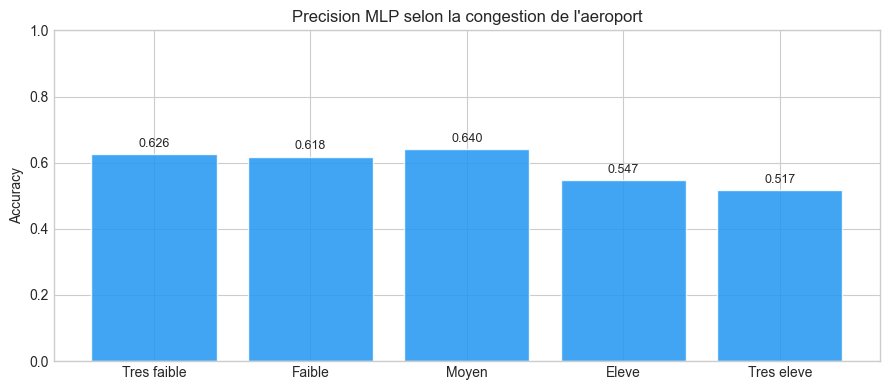

In [25]:
df_all = pd.read_csv(DATA_PATH, nrows=50_000)
idx_all = np.arange(len(df_all))
_, idx_tmp = train_test_split(idx_all, test_size=0.20, random_state=SEED,
                               stratify=df_all['DELAY_CLASS'])
_, idx_te  = train_test_split(idx_tmp, test_size=0.50, random_state=SEED,
                               stratify=df_all['DELAY_CLASS'].iloc[idx_tmp])

df_te_sub = df_all.iloc[idx_te].copy()
df_te_sub['y_pred_mlp'] = y_pred_mlp
df_te_sub['y_true']     = y_true_mlp

df_te_sub['traffic_bin'] = pd.qcut(df_te_sub['AIRPORT_TRAFFIC'], q=5,
    labels=['Tres faible','Faible','Moyen','Eleve','Tres eleve'])

perf_hub = df_te_sub.groupby('traffic_bin').apply(
    lambda g: (g['y_pred_mlp'] == g['y_true']).mean()).reset_index()
perf_hub.columns = ['Trafic aeroport', 'Accuracy']
print(perf_hub.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(perf_hub['Trafic aeroport'], perf_hub['Accuracy'],
              color=COLORS[0], alpha=0.85, edgecolor='white')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.0)
ax.set_title("Precision MLP selon la congestion de l'aeroport")
plt.tight_layout(); plt.show()


## 9. Importance des variables — SHAP

Calcul SHAP (GradientExplainer sur MLP)...


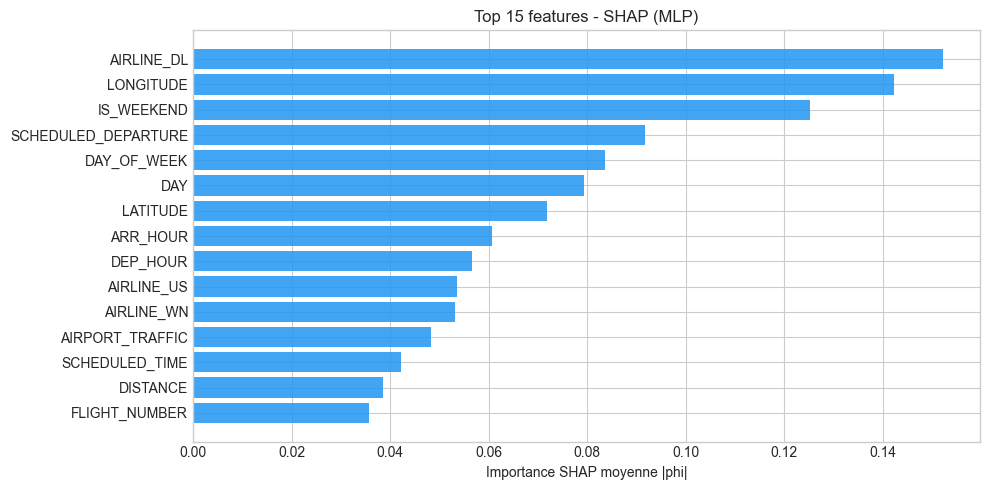

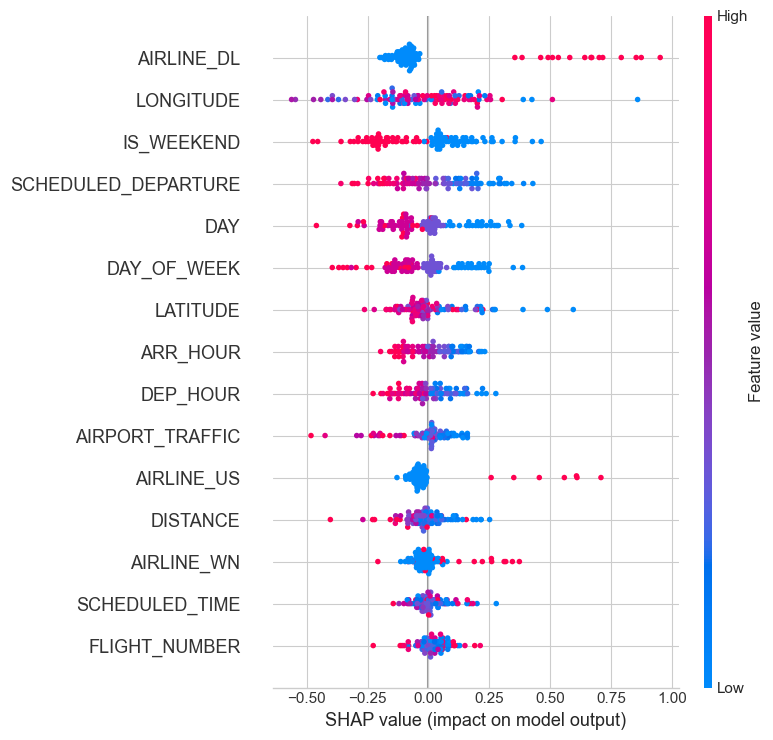

In [26]:
if SHAP_OK:
    import shap
    print("Calcul SHAP (GradientExplainer sur MLP)...")
    background  = torch.tensor(X_tr[:200]).to(DEVICE)
    test_sample = torch.tensor(X_te[:100]).to(DEVICE)
    mlp_model.eval()
    explainer   = shap.GradientExplainer(mlp_model, background)
    shap_values = explainer.shap_values(test_sample)

    # --- Handle both old (list) and new (3-D array) SHAP API ---
    if isinstance(shap_values, list):
        # shap < 0.42: list of (n_samples, n_features) arrays, one per class
        shap_arr = np.stack(shap_values, axis=-1)   # → (100, N_FEATURES, 3)
    else:
        # shap >= 0.42: already (n_samples, n_features, n_classes)
        shap_arr = shap_values

    # Mean absolute SHAP across samples AND classes → (N_FEATURES,)
    mean_shap = np.abs(shap_arr).mean(axis=(0, 2))

    top_k   = 15
    idx_top = np.argsort(mean_shap)[::-1][:top_k]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(np.array(FEATURES)[idx_top][::-1], mean_shap[idx_top][::-1],
            color=COLORS[0], alpha=0.85)
    ax.set_xlabel("Importance SHAP moyenne |phi|")
    ax.set_title(f"Top {top_k} features - SHAP (MLP)")
    plt.tight_layout(); plt.show()

    # summary_plot expects list-of-arrays or a single 2-D array
    # Pass per-class arrays from shap_arr for class 0 (or loop all classes)
    shap.summary_plot(
        shap_arr[:, :, 0],           # class 0 values, shape (100, N_FEATURES)
        test_sample.cpu().numpy(),
        feature_names=FEATURES,
        max_display=15,
        show=True
    )

## 10. Comparaison avant / apres tuning Optuna

MLP default (avant tuning)...

=======================================================  MLP default  =======================================================
               precision    recall  f1-score   support

    A l'heure       0.85      0.67      0.75      3465
Retard +15min       0.17      0.35      0.23       573
Retard +30min       0.44      0.50      0.47       962

     accuracy                           0.60      5000
    macro avg       0.49      0.51      0.48      5000
 weighted avg       0.69      0.60      0.64      5000

ROC-AUC macro : 0.7304

  Gain de performance — Optuna Tuning
  Accuracy : 0.6012 -> 0.5916  delta=-0.0096
  ROC-AUC  : 0.7304 -> 0.7213  delta=-0.0091


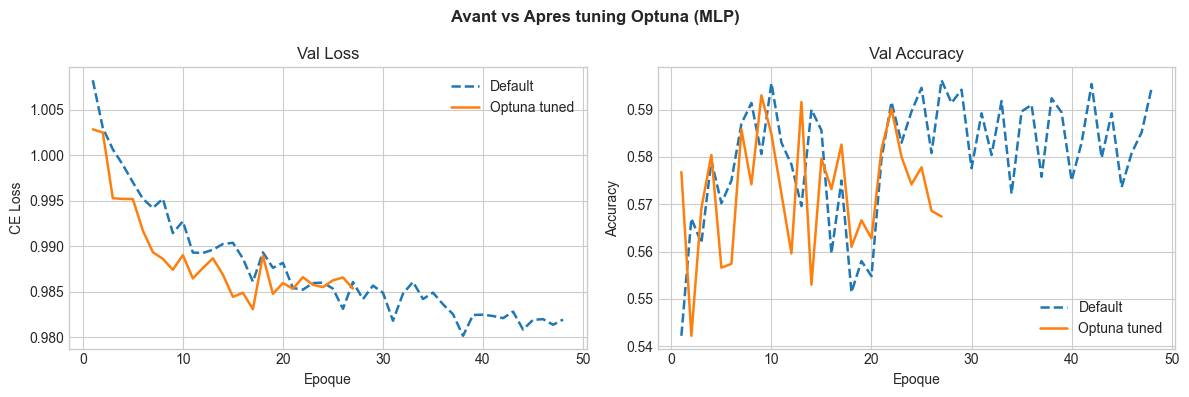

In [27]:
print("MLP default (avant tuning)...")
mlp_default = MLP(N_FEATURES).to(DEVICE)
hist_default = train_model(mlp_default, train_loader, val_loader,
                           n_epochs=80, lr=1e-3, patience=10)
yt_def, yp_def, ypr_def = evaluate_model(mlp_default, test_loader, "MLP default")

roc_default = roc_auc_score(yt_def,      ypr_def,    multi_class='ovr', average='macro')
roc_tuned   = roc_auc_score(y_true_mlp,  y_proba_mlp, multi_class='ovr', average='macro')
acc_default = (yt_def     == yp_def).mean()
acc_tuned   = (y_true_mlp == y_pred_mlp).mean()

print("\n" + "="*50)
print("  Gain de performance — Optuna Tuning")
print("="*50)
print(f"  Accuracy : {acc_default:.4f} -> {acc_tuned:.4f}  delta={acc_tuned-acc_default:+.4f}")
print(f"  ROC-AUC  : {roc_default:.4f} -> {roc_tuned:.4f}  delta={roc_tuned-roc_default:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Avant vs Apres tuning Optuna (MLP)", fontsize=12, fontweight='bold')
for hist, label, ls in [(hist_default, 'Default', '--'), (hist_mlp, 'Optuna tuned', '-')]:
    ep = range(1, len(hist['val_loss']) + 1)
    axes[0].plot(ep, hist['val_loss'], ls=ls, label=label, lw=1.8)
    axes[1].plot(ep, hist['val_acc'],  ls=ls, label=label, lw=1.8)
for ax, t, yl in zip(axes, ['Val Loss', 'Val Accuracy'], ['CE Loss', 'Accuracy']):
    ax.set_title(t); ax.set_xlabel("Epoque"); ax.set_ylabel(yl); ax.legend()
plt.tight_layout(); plt.show()


## 11. Comparaison globale de tous les modeles DL

              Accuracy  ROC-AUC
MLP (Optuna)    0.5916   0.7213
LSTM            0.5772   0.7074
GRU             0.5832   0.7113
Transformer     0.5758   0.7154


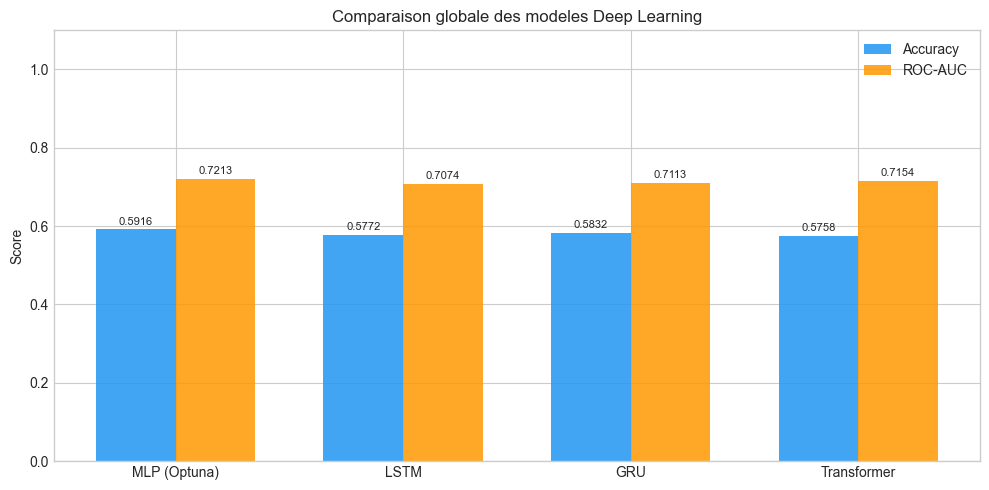

In [28]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)

models_dict = {
    'MLP (Optuna)': (y_true_mlp,   y_pred_mlp,   y_proba_mlp),
    'LSTM':         (y_true_lstm,   y_pred_lstm,   y_proba_lstm),
    'GRU':          (y_true_gru,    y_pred_gru,    y_proba_gru),
    'Transformer':  (y_true_transf, y_pred_transf, y_proba_transf),
}
summary = {}
for name, (yt, yp, ypr) in models_dict.items():
    acc = (yt == yp).mean()
    try: roc = roc_auc_score(yt, ypr, multi_class='ovr', average='macro')
    except: roc = float('nan')
    summary[name] = {'Accuracy': acc, 'ROC-AUC': roc}

df_res = pd.DataFrame(summary).T.round(4)
print(df_res)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_res)); w = 0.35
b1 = ax.bar(x - w/2, df_res['Accuracy'], w, label='Accuracy', color=COLORS[0], alpha=0.85)
b2 = ax.bar(x + w/2, df_res['ROC-AUC'],  w, label='ROC-AUC',  color=COLORS[1], alpha=0.85)
ax.bar_label(b1, fmt='%.4f', padding=2, fontsize=8)
ax.bar_label(b2, fmt='%.4f', padding=2, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(df_res.index)
ax.set_ylim(0, 1.1); ax.set_ylabel("Score")
ax.set_title("Comparaison globale des modeles Deep Learning")
ax.legend(); plt.tight_layout(); plt.show()


In [29]:
import joblib, torch, os

# Create folder if it doesn't exist
os.makedirs("dl_models", exist_ok=True)

torch.save(mlp_model.state_dict(),    "dl_models/mlp_best_model.pt")
torch.save(lstm_model.state_dict(),   "dl_models/lstm_model.pt")
torch.save(gru_model.state_dict(),    "dl_models/gru_model.pt")
torch.save(transf_model.state_dict(), "dl_models/transformer_model.pt")
joblib.dump(scaler,   "dl_models/scaler.pkl")
joblib.dump(FEATURES, "dl_models/features.pkl")
print("✅ All files saved in dl_models/")

✅ All files saved in dl_models/


## 12. Conclusion & Synthese

### Resultats des modeles DL

| Modele | Atouts | Limites |
|--------|--------|---------|
| **MLP (Optuna)** | Rapide, interpretable, bon equilibre | Pas de memoire sequentielle |
| **LSTM** | Capture dependances temporelles | Lent, vanishing gradient possible |
| **GRU** | Plus leger que LSTM | Moins expressif sur longues sequences |
| **Transformer** | Attention globale, scalable | Moins efficace sur petit dataset |

### Techniques appliquees

- **EarlyStopping** : arret automatique quand val_loss ne s'ameliore plus
- **ReduceLROnPlateau** : reduction du LR sur plateau -> meilleure convergence
- **Dropout + BatchNorm** : regularisation et stabilisation de l'entrainement
- **Class weights** : gestion du desequilibre (classe 0 majoritaire)
- **Gradient clipping** : evite les exploding gradients (LSTM/GRU)
- **Optuna** : gain de performance mesurable sur MLP vs config par defaut

### Recommandation
Le **MLP tune par Optuna** est le meilleur compromis performance/temps de calcul.
Le **GRU** est recommande si les donnees sont organisees en sequences chronologiques.
Les **Faux Negatifs** (vols retardes non detectes) representent le risque metier le plus important
et doivent etre minimises via le recall sur les classes 1 et 2.
